Handwritten Digit Classification

Subtitle: Recognition of Handwritten Digits Using Machine Learning

Dataset: UCI Optical Recognition of Handwritten Digits

Algorithms: K-Nearest Neighbors (KNN) and Support Vector Machine (SVM)

Library Import

In [72]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

Model Libraries

In [4]:
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

Dataset Loading

In [6]:
df_train = pd.read_csv("optdigits.tra", header=None)
df_test = pd.read_csv("optdigits.tes", header=None)

Data Inspection

In [7]:
df_train.sample(10)

,0,1,2,3,4,5,6,7,8,9,...,55,56,57,58,59,60,61,62,63,64
3358,0,0,0,9,15,4,0,0,0,0,...,0,0,0,0,8,15,16,11,0,6
845,0,0,6,9,13,7,0,0,0,7,...,0,0,0,4,15,13,8,0,0,3
390,0,0,13,16,6,0,0,0,0,6,...,0,0,1,11,15,16,16,3,0,2
1178,0,0,3,12,15,3,0,0,0,0,...,0,0,0,6,11,16,14,3,0,5
2302,0,6,16,16,16,12,0,0,0,0,...,0,0,5,16,1,0,0,0,0,7
3541,0,0,10,15,16,16,9,0,0,1,...,0,0,0,9,16,10,2,0,0,3
3309,0,0,0,4,15,7,0,0,0,0,...,0,0,0,0,5,16,5,0,0,4
1851,0,0,0,7,16,11,0,0,0,0,...,0,0,0,0,8,16,1,0,0,9
559,0,0,5,12,12,3,0,0,0,1,...,0,0,0,10,16,13,4,0,0,9
3447,0,0,10,8,10,12,6,0,0,2,...,0,0,0,14,10,0,0,0,0,7


In [8]:
df_train.head(10)

,0,1,2,3,4,5,6,7,8,9,...,55,56,57,58,59,60,61,62,63,64
0,0,1,6,15,12,1,0,0,0,7,...,0,0,0,6,14,7,1,0,0,0
1,0,0,10,16,6,0,0,0,0,7,...,0,0,0,10,16,15,3,0,0,0
2,0,0,8,15,16,13,0,0,0,1,...,0,0,0,9,14,0,0,0,0,7
3,0,0,0,3,11,16,0,0,0,0,...,0,0,0,0,1,15,2,0,0,4
4,0,0,5,14,4,0,0,0,0,0,...,0,0,0,4,12,14,7,0,0,6
5,0,0,11,16,10,1,0,0,0,4,...,3,0,0,10,16,16,16,16,6,2
6,0,0,1,11,13,11,7,0,0,0,...,0,0,0,1,13,5,0,0,0,5
7,0,0,8,10,8,7,2,0,0,1,...,0,0,0,4,13,8,0,0,0,5
8,0,0,15,2,14,13,2,0,0,0,...,0,0,0,10,12,5,0,0,0,0
9,0,0,3,13,13,2,0,0,0,6,...,0,0,0,3,15,11,6,0,0,8


In [9]:
df_train.tail(10)

,0,1,2,3,4,5,6,7,8,9,...,55,56,57,58,59,60,61,62,63,64
3813,0,0,0,6,8,0,0,0,0,0,...,0,0,1,4,9,8,0,0,0,4
3814,0,0,9,16,6,0,0,0,0,2,...,0,0,0,10,13,1,0,0,0,8
3815,0,0,9,16,12,1,0,0,0,3,...,0,0,0,8,16,16,16,8,0,9
3816,0,1,10,16,16,4,0,0,0,8,...,0,0,2,13,16,12,5,0,0,3
3817,0,0,6,16,11,0,0,0,0,1,...,0,0,1,7,14,16,12,1,0,9
3818,0,0,5,13,11,2,0,0,0,2,...,0,0,0,8,13,15,10,1,0,9
3819,0,0,0,1,12,1,0,0,0,0,...,0,0,0,0,4,9,0,0,0,4
3820,0,0,3,15,0,0,0,0,0,0,...,0,0,0,4,14,16,9,0,0,6
3821,0,0,6,16,2,0,0,0,0,0,...,0,0,0,5,16,16,16,5,0,6
3822,0,0,2,15,16,13,1,0,0,0,...,0,0,0,4,14,1,0,0,0,7


Dataset Information

In [10]:
df_train.shape

(3823, 65)

In [11]:
df_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 3823 entries, 0 to 3822
Data columns (total 65 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   0       3823 non-null   int64
 1   1       3823 non-null   int64
 2   2       3823 non-null   int64
 3   3       3823 non-null   int64
 4   4       3823 non-null   int64
 5   5       3823 non-null   int64
 6   6       3823 non-null   int64
 7   7       3823 non-null   int64
 8   8       3823 non-null   int64
 9   9       3823 non-null   int64
 10  10      3823 non-null   int64
 11  11      3823 non-null   int64
 12  12      3823 non-null   int64
 13  13      3823 non-null   int64
 14  14      3823 non-null   int64
 15  15      3823 non-null   int64
 16  16      3823 non-null   int64
 17  17      3823 non-null   int64
 18  18      3823 non-null   int64
 19  19      3823 non-null   int64
 20  20      3823 non-null   int64
 21  21      3823 non-null   int64
 22  22      3823 non-null   int64
 23  23      3823 non-null   

Missing & Duplicate Value Checking

In [13]:
df_train.isnull().sum()

0     0
1     0
2     0
3     0
4     0
     ..
60    0
61    0
62    0
63    0
64    0
Length: 65, dtype: int64

In [15]:
df_train.describe()

,0,1,2,3,4,5,6,7,8,9,...,55,56,57,58,59,60,61,62,63,64
count,3823.0,3823.000000,3823.000000,3823.000000,3823.000000,3823.000000,3823.000000,3823.000000,3823.000000,3823.000000,...,3823.000000,3823.000000,3823.000000,3823.000000,3823.000000,3823.000000,3823.000000,3823.000000,3823.000000,3823.000000
mean,0.0,0.301334,5.481821,11.805912,11.451478,5.505362,1.387392,0.142297,0.002093,1.960502,...,0.148313,0.000262,0.283024,5.855872,11.942977,11.461156,6.700497,2.105676,0.202197,4.497253
std,0.0,0.866986,4.631601,4.259811,4.537556,5.613060,3.371444,1.051598,0.088572,3.052353,...,0.767761,0.016173,0.928046,4.980012,4.334508,4.991934,5.775815,4.028266,1.150694,2.869831
min,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.0,0.000000,1.000000,10.000000,9.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,1.000000,10.000000,9.000000,0.000000,0.000000,0.000000,2.000000
50%,0.0,0.000000,5.000000,13.000000,13.000000,4.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,5.000000,13.000000,13.000000,6.000000,0.000000,0.000000,4.000000
75%,0.0,0.000000,9.000000,15.000000,15.000000,10.000000,0.000000,0.000000,0.000000,3.000000,...,0.000000,0.000000,0.000000,10.000000,15.000000,16.000000,12.000000,2.000000,0.000000,7.000000
max,0.0,8.000000,16.000000,16.000000,16.000000,16.000000,16.000000,16.000000,5.000000,15.000000,...,12.000000,1.000000,10.000000,16.000000,16.000000,16.000000,16.000000,16.000000,16.000000,9.000000


In [19]:
df_test.isnull().sum()

0     0
1     0
2     0
3     0
4     0
     ..
60    0
61    0
62    0
63    0
64    0
Length: 65, dtype: int64

In [20]:
df_test.duplicated().sum()

np.int64(0)

Digit Distribution

In [21]:
df_train[64].value_counts()

64
1    389
3    389
7    387
4    387
9    382
2    380
8    380
6    377
0    376
5    376
Name: count, dtype: int64

In [22]:
df_train[64].value_counts().sort_index(ascending=True)

64
0    376
1    389
2    380
3    389
4    387
5    376
6    377
7    387
8    380
9    382
Name: count, dtype: int64

In [23]:
df_train[64].value_counts().sort_values(ascending=False)

64
1    389
3    389
7    387
4    387
9    382
2    380
8    380
6    377
0    376
5    376
Name: count, dtype: int64

Data Visualization

Text(0, 0.5, 'Count')

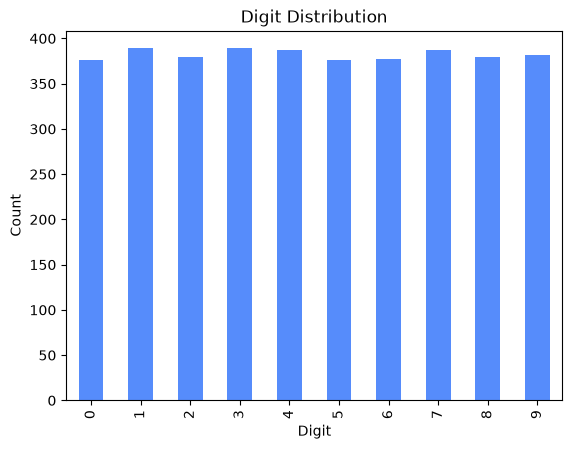

In [24]:
df_train[64].value_counts().sort_index().plot(kind='bar')

plt.title('Digit Distribution')
plt.xlabel('Digit')
plt.ylabel('Count')

Text(0.5, 1.0, 'Handwritten Digit')

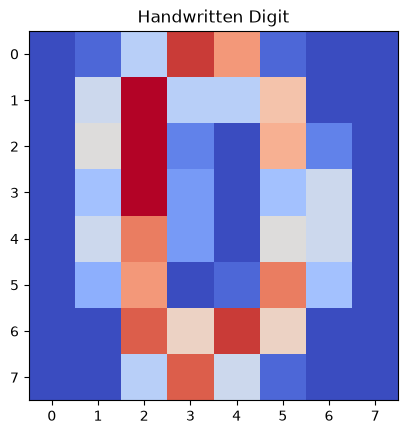

In [25]:
plt.imshow(df_train.iloc[0, :64].values.reshape(8,8), cmap='coolwarm')
plt.title('Handwritten Digit')

Feature & Target Selection

In [26]:
X_train = df_train.iloc[:, :64]
y_train = df_train.iloc[:, 64]

X_test = df_test.iloc[:, :64]
y_test = df_test.iloc[:, 64]

Feature Scaling

In [27]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

KNN Model

In [28]:
knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train, y_train)

knn_pred = knn.predict(X_test)

print("KNN Accuracy:", accuracy_score(y_test, knn_pred))

KNN Accuracy: 0.9649415692821369


SVM Model

In [29]:
svm = SVC()

svm.fit(X_train, y_train)

svm_pred = svm.predict(X_test)

print("SVM Accuracy:", accuracy_score(y_test, svm_pred))

SVM Accuracy: 0.9677239844184753


Model Comparison

In [30]:
results = pd.DataFrame({
    'Model': ['KNN', 'SVM'],
    'Accuracy': [
        accuracy_score(y_test, knn_pred),
        accuracy_score(y_test, svm_pred)
    ]
})

print(results)

  Model  Accuracy
0   KNN  0.964942
1   SVM  0.967724


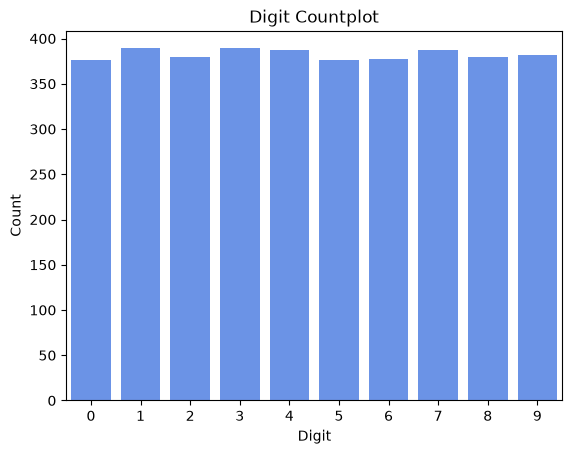

In [64]:
sns.countplot(x=df_train[64])
plt.title('Digit Countplot')
plt.xlabel('Digit')
plt.ylabel('Count')
plt.show()

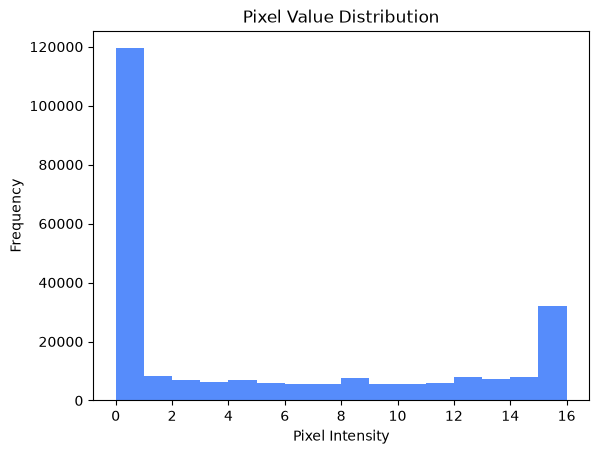

In [65]:
plt.hist(df_train.iloc[:, :64].values.flatten(), bins=16)
plt.title('Pixel Value Distribution')
plt.xlabel('Pixel Intensity')
plt.ylabel('Frequency')
plt.show()

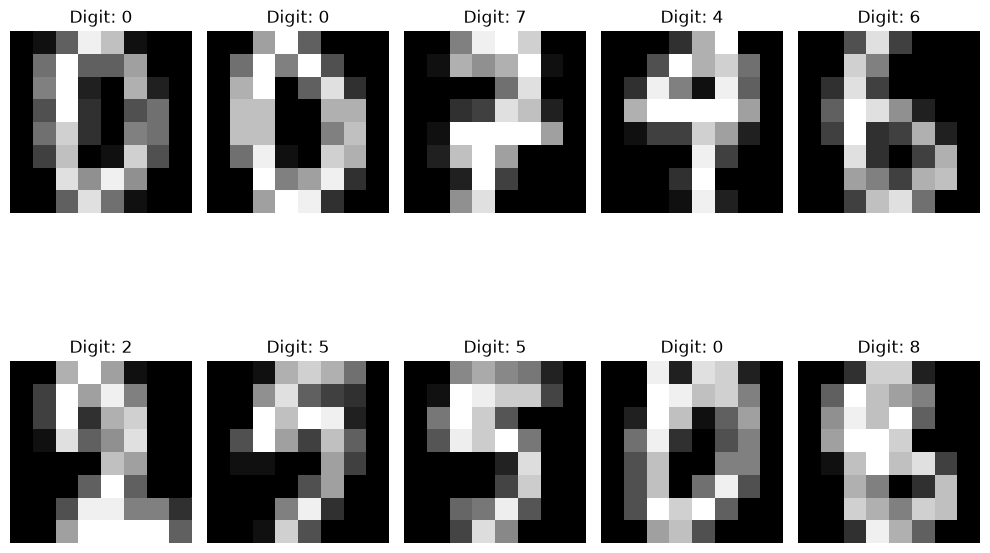

In [69]:
plt.figure(figsize=(10, 8))

for i in range(10):
    plt.subplot(2, 5, i+1)
    plt.imshow(df_train.iloc[i, :64].values.reshape(8, 8), cmap='gray')
    plt.title(f'Digit: {df_train.iloc[i, 64]}')
    plt.axis('off')

plt.tight_layout()
plt.show()

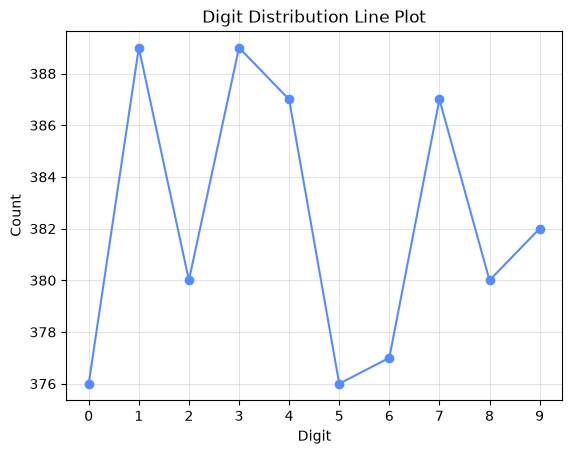

In [70]:
digit_count = df_train[64].value_counts().sort_index()

plt.plot(digit_count.index, digit_count.values, marker='o')
plt.title('Digit Distribution Line Plot')
plt.xlabel('Digit')
plt.ylabel('Count')
plt.xticks(range(10))
plt.grid()
plt.show()

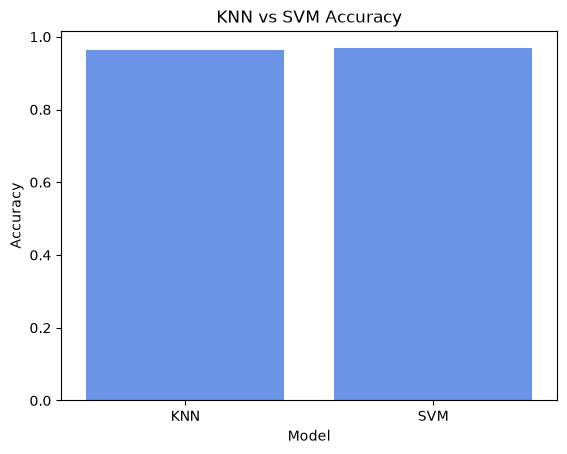

In [71]:
sns.barplot(x='Model', y='Accuracy', data=results)
plt.title('KNN vs SVM Accuracy')
plt.show()

Classification Report

In [38]:
print(classification_report(y_test, svm_pred))

              precision    recall  f1-score   support

           0       0.99      0.99      0.99       178
           1       0.92      0.98      0.95       182
           2       0.98      0.94      0.96       177
           3       0.99      0.95      0.97       183
           4       0.94      0.99      0.96       181
           5       0.98      0.99      0.99       182
           6       0.99      0.99      0.99       181
           7       0.99      0.96      0.97       179
           8       0.98      0.91      0.94       174
           9       0.92      0.97      0.94       180

    accuracy                           0.97      1797
   macro avg       0.97      0.97      0.97      1797
weighted avg       0.97      0.97      0.97      1797



Sample Prediction

In [39]:
sample = X_test[0].reshape(1, -1)

prediction = svm.predict(sample)

print("Predicted Digit:", prediction[0])
print("Actual Digit:", y_test.iloc[0])

Predicted Digit: 0
Actual Digit: 0


Dataset Shape

In [40]:
print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (3823, 64)
Testing Data: (1797, 64)


KNN & SVM Optimization

In [41]:
from sklearn.model_selection import GridSearchCV

params = {'n_neighbors': [3, 5, 7, 9]}

grid = GridSearchCV(KNeighborsClassifier(), params, cv=3)

grid.fit(X_train, y_train)

print("Best Parameter:", grid.best_params_)
print("Best Score:", grid.best_score_)

Best Parameter: {'n_neighbors': 3}
Best Score: 0.9733193790336648


In [42]:
best_knn = grid.best_estimator_

best_knn_pred = best_knn.predict(X_test)

print("Best KNN Accuracy:",
      accuracy_score(y_test, best_knn_pred) * 100)

Best KNN Accuracy: 96.4941569282137


In [44]:
params = {
    'C': [1, 10],
    'kernel': ['linear', 'rbf']
}

grid_svm = GridSearchCV(SVC(), params, cv=3)

grid_svm.fit(X_train, y_train)

print("Best Parameters:", grid_svm.best_params_)
print("Best Score:", grid_svm.best_score_)

Best Parameters: {'C': 10, 'kernel': 'rbf'}
Best Score: 0.9856135274622669


In [45]:
best_svm = grid_svm.best_estimator_

best_svm_pred = best_svm.predict(X_test)

print("Best SVM Accuracy:",
      accuracy_score(y_test, best_svm_pred) * 100)

Best SVM Accuracy: 97.10628825820812


Final Model Comparison

In [46]:
final_results = pd.DataFrame({
    'Model': ['Best KNN', 'Best SVM'],
    'Accuracy': [
        accuracy_score(y_test, best_knn_pred) * 100,
        accuracy_score(y_test, best_svm_pred) * 100
    ]
})

print(final_results)

      Model   Accuracy
0  Best KNN  96.494157
1  Best SVM  97.106288


Best Model Evaluation

In [56]:
print("Best KNN Report")
print(classification_report(y_test, best_knn_pred))

print("Best SVM Report")
print(classification_report(y_test, best_svm_pred))

Best KNN Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       178
           1       0.89      0.99      0.94       182
           2       0.98      0.93      0.95       177
           3       0.97      0.96      0.96       183
           4       0.99      0.97      0.98       181
           5       0.96      0.99      0.98       182
           6       0.97      1.00      0.99       181
           7       0.99      0.98      0.98       179
           8       0.95      0.90      0.92       174
           9       0.96      0.94      0.95       180

    accuracy                           0.96      1797
   macro avg       0.97      0.96      0.96      1797
weighted avg       0.97      0.96      0.96      1797

Best SVM Report
              precision    recall  f1-score   support

           0       0.99      1.00      1.00       178
           1       0.94      0.98      0.96       182
           2       0.98      0.94      0.96   

Best Model Selection

In [57]:
if accuracy_score(y_test, best_knn_pred) > accuracy_score(y_test, best_svm_pred):
    print("Best KNN performs better")
else:
    print("Best SVM performs better")

Best SVM performs better


Project Information

In [49]:
print("Project: Handwritten Digit Classification")
print("Dataset: UCI Optical Recognition of Handwritten Digits")
print("Algorithms: KNN and SVM")
print("Task: Recognizing handwritten digits from 0 to 9")

Project: Handwritten Digit Classification
Dataset: UCI Optical Recognition of Handwritten Digits
Algorithms: KNN and SVM
Task: Recognizing handwritten digits from 0 to 9


Model Saving

In [51]:
import joblib

joblib.dump(best_svm, 'best_digit_model.pkl')
joblib.dump(scaler, 'scaler.pkl')

print("Model Saved Successfully")

Model Saved Successfully


Confusion Matrix

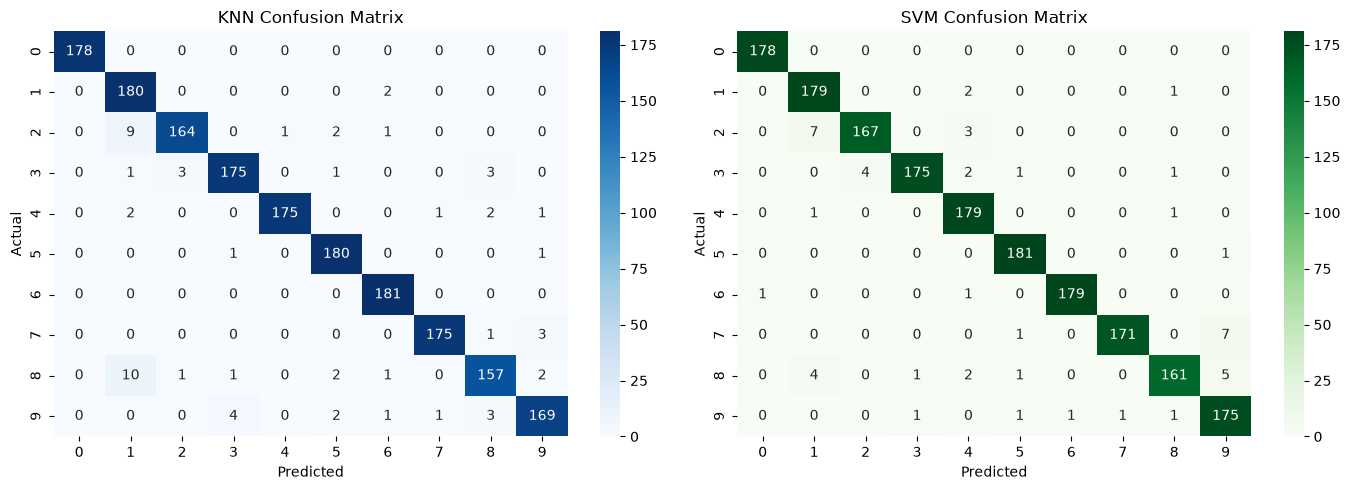

In [74]:
knn_cm = confusion_matrix(y_test, best_knn_pred)
svm_cm = confusion_matrix(y_test, best_svm_pred)

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
sns.heatmap(knn_cm, annot=True, fmt='d', cmap='Blues')
plt.title('KNN Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.subplot(1, 2, 2)
sns.heatmap(svm_cm, annot=True, fmt='d', cmap='Greens')
plt.title('SVM Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.tight_layout()
plt.show()

Actual Vs Predicted

In [60]:
comparison = pd.DataFrame({
    'Actual': y_test.iloc[:20].values,
    'Predicted': best_svm_pred[:20]
})

print(comparison)

    Actual  Predicted
0        0          0
1        1          1
2        2          1
3        3          3
4        4          4
5        5          9
6        6          6
7        7          7
8        8          8
9        9          9
10       0          0
11       1          1
12       2          2
13       3          3
14       4          4
15       5          5
16       6          6
17       7          7
18       8          8
19       9          9


Final Accuracy

In [62]:
print("Best SVM Accuracy:", accuracy_score(y_test, svm_pred)*100)

Best SVM Accuracy: 96.77239844184753


Conclusion
- Dataset contains handwritten digits from 0 to 9.
- Each image contains 64 pixel features.
- KNN and SVM models were trained.
- GridSearchCV was used for hyperparameter tuning.
- The model with higher accuracy was selected as the best model.